In [1]:
import pandas as pd
import numpy as np
import joblib
import matplotlib.pyplot as plt

from lime.lime_tabular import LimeTabularExplainer

print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
X_train = pd.read_csv(
    "../datasets/processed/diabetes/x_train.csv"
)

X_test = pd.read_csv(
    "../datasets/processed/diabetes/x_test.csv"
)

y_train = pd.read_csv(
    "../datasets/processed/diabetes/y_train.csv"
).squeeze()

y_test = pd.read_csv(
    "../datasets/processed/diabetes/y_test.csv"
).squeeze()

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

X_train: (416, 16)
X_test : (104, 16)
y_train: (416,)
y_test : (104,)


In [3]:
model = joblib.load(
    "../models/diabetes/best_model.pkl"
)

print("Model loaded successfully.")
print(model)

Model loaded successfully.
DecisionTreeClassifier(random_state=42)


In [4]:
explainer = LimeTabularExplainer(
    training_data=X_train.values,
    feature_names=X_train.columns.tolist(),
    class_names=["Negative", "Positive"],
    mode="classification",
    random_state=42
)

print("LIME explainer created successfully.")

LIME explainer created successfully.


In [5]:
patient_index = 0

patient = X_test.iloc[patient_index].values

print("Patient index:", patient_index)
print("Patient data:")
print(patient)

Patient index: 0
Patient data:
[ 0.16795255 -1.30433842 -0.9904304  -0.88623232 -0.86057293  0.81895222
 -0.9258201  -0.54401301  1.10125654  1.02927447 -0.54030127  1.06458129
 -0.87333376 -0.77062944  1.4040757  -0.46133284]


In [6]:
lime_explanation = explainer.explain_instance(
    patient,
    model.predict_proba,
    num_features=16
)

print("LIME explanation generated successfully.")

LIME explanation generated successfully.


d:\Explainable-AI-CDSS\.venv\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


In [8]:
print("LIME Explanation:")
for feature, weight in lime_explanation.as_list():
    print(f"{feature}: {weight:.4f}")

LIME Explanation:
Polyuria <= -0.99: -0.4564
Polydipsia <= -0.89: -0.2196
-0.94 < delayed healing <= 1.06: 0.1517
Obesity <= -0.46: 0.1363
muscle stiffness <= -0.77: 0.1324
-0.71 < Alopecia <= 1.40: -0.0721
Genital thrush <= -0.54: -0.0501
partial paresis <= -0.87: -0.0466
-0.97 < Itching <= 1.03: -0.0373
0.00 < Age <= 0.75: -0.0338
-1.22 < weakness <= 0.82: 0.0278
Polyphagia <= -0.93: -0.0258
sudden weight loss <= -0.86: -0.0165
Irritability <= -0.54: 0.0133
Gender <= -1.30: -0.0093
-0.91 < visual blurring <= 1.10: -0.0040


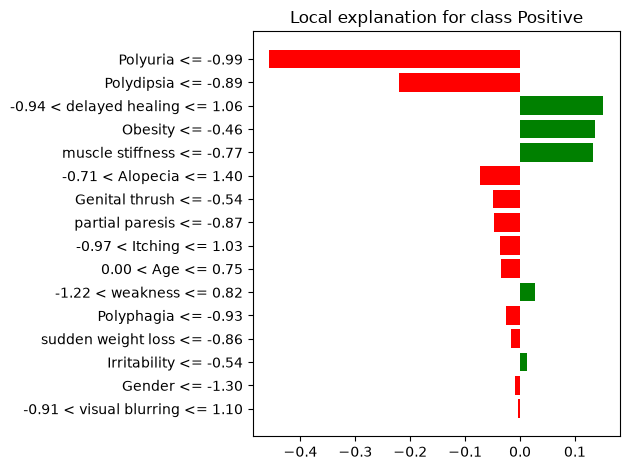

In [9]:
fig = lime_explanation.as_pyplot_figure()

plt.tight_layout()
plt.show()

In [10]:
prediction = model.predict(X_test.iloc[[patient_index]])[0]
probability = model.predict_proba(
    X_test.iloc[[patient_index]]
)[0]

print("Predicted Class:", prediction)

if prediction == 1:
    print("Prediction: Positive")
else:
    print("Prediction: Negative")

print("\nClass Probabilities:")
print("Negative:", round(probability[0], 4))
print("Positive:", round(probability[1], 4))

Predicted Class: 0
Prediction: Negative

Class Probabilities:
Negative: 1.0
Positive: 0.0


In [11]:
for feature, weight in lime_explanation.as_list():
    print(f"{feature}: {weight:.4f}")

Polyuria <= -0.99: -0.4564
Polydipsia <= -0.89: -0.2196
-0.94 < delayed healing <= 1.06: 0.1517
Obesity <= -0.46: 0.1363
muscle stiffness <= -0.77: 0.1324
-0.71 < Alopecia <= 1.40: -0.0721
Genital thrush <= -0.54: -0.0501
partial paresis <= -0.87: -0.0466
-0.97 < Itching <= 1.03: -0.0373
0.00 < Age <= 0.75: -0.0338
-1.22 < weakness <= 0.82: 0.0278
Polyphagia <= -0.93: -0.0258
sudden weight loss <= -0.86: -0.0165
Irritability <= -0.54: 0.0133
Gender <= -1.30: -0.0093
-0.91 < visual blurring <= 1.10: -0.0040
